# mnist2.ipynb

The intent of this notebook is to explore use of [k-fold cross-validation](https://docs.cleanlab.ai/v2.0.0/tutorials/pred_probs_cross_val.html)
to calculate **out-of-sample predicted probabilities**.

[CleanLearning](https://share.google/aimode/nSa6rBxStItaBAErO)

[cross_val_predict](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html).

We start with a copy of **src/mnist-classification-using-random-forest.ipynb**.

- The first mod is to combine training and test datasets.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in 

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list the files in the input directory

from subprocess import check_output
print(check_output(["ls", "../input"]).decode("utf8"))

# Any results you write to the current directory are saved as output.

mnist_rf.csv
test.csv
train.csv



In [2]:
# Load other modules
import matplotlib.pyplot as plt  #Graphics
from sklearn.ensemble import RandomForestClassifier  #Random Forest algorithm
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_predict
from icecream import ic  #To debug and print variables
from cleanlab.datalab.datalab import Datalab
from cleanlab.filter import find_label_issues
#To show graphs within the notebook
%matplotlib inline 

### Prepare data

In [3]:
#load the datasets
train = pd.read_csv("../input/train.csv")
test = pd.read_csv("../input/test.csv")
test_labels = pd.read_csv("../input/mnist_rf.csv")

# add label column to test dataset
test['label'] = test_labels['Label']

# combine train and test datasets
combined = pd.concat([train, test], ignore_index=True)

ic(train.shape, test.shape, test_labels.shape, combined.shape);

ic| train.shape: (42000, 785)
    test.shape: (28000, 785)
    test_labels.shape: (28000, 2)
    combined.shape: (70000, 785)


### Perform K-fold cross-validation predictions

In [4]:
X = combined.drop('label', axis=1)
y = combined['label']
rf = RandomForestClassifier(n_estimators=100)
pred_probs = cross_val_predict(
    rf,
    X,
    y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    method="predict_proba",
)

In [5]:
cm_prior = confusion_matrix(y, np.argmax(pred_probs, axis=1))
print("Confusion Matrix (Prior to Cleaning):")
print(cm_prior)
accuracy = np.diag(cm_prior).sum() / cm_prior.sum()
print(f'accuracy: {accuracy:.4f}')

Confusion Matrix (Prior to Cleaning):
[[6841    0    4    8    3    9   20    0   25    6]
 [   0 7788   24   16   10    6    8   11   13    6]
 [  20    8 6845   33   19    2   19   39   38    4]
 [   8    7   80 6850    5   58    5   35   52   25]
 [   6    9   13    1 6654    0   21    8   13  105]
 [  19    8    7   83    8 6061   38    4   32   26]
 [  29    7   10    2   11   37 6800    0   19    1]
 [   5   21   69    8   24    1    0 7063   13   81]
 [   8   27   29   46   17   34   21    7 6518   58]
 [  22    9   13   64   83   25    5   58   43 6646]]
accuracy: 0.9724


### Run Datalab to find database issues

In [6]:
lab = Datalab(data=combined, label_name='label')
lab.find_issues(pred_probs=pred_probs)
lab.report(verbosity=3)  # Summarizes the issues found

Finding label issues ...
Finding outlier issues ...
Fitting OOD estimator based on provided pred_probs ...
Finding non_iid issues ...
Finding class_imbalance issues ...

Audit complete. 45 issues found in the dataset.
Dataset Information: num_examples: 70000, num_classes: 10

Here is a summary of various issues found in your data:

issue_type  num_issues
     label          43
   outlier           1
   non_iid           1

Learn about each issue: https://docs.cleanlab.ai/stable/cleanlab/datalab/guide/issue_type_description.html
See which examples in your dataset exhibit each issue via: `datalab.get_issues(<ISSUE_NAME>)`

Data indices corresponding to top examples of each issue are shown below.


----------------------- label issues -----------------------

About this issue:
	Examples whose given label is estimated to be potentially incorrect
    (e.g. due to annotation error) are flagged as having label issues.
    

Number of examples with this issue: 43
Overall dataset quality in ter

### Analyse issues

In [7]:
lab.get_issues()

,is_label_issue,label_score,is_outlier_issue,outlier_score,is_non_iid_issue,non_iid_score,is_class_imbalance_issue,class_imbalance_score
0,False,1.00,False,0.177808,False,0.538681,False,1.0
1,False,0.98,False,0.212258,False,0.968427,False,1.0
2,False,1.00,False,0.177808,False,0.538672,False,1.0
3,False,0.45,False,0.076663,False,0.883204,False,1.0
4,False,1.00,False,0.218626,False,0.540717,False,1.0
...,...,...,...,...,...,...,...,...
69995,False,0.91,False,0.235958,False,0.980518,False,1.0
69996,False,0.98,False,0.227716,False,0.570659,False,1.0
69997,False,1.00,False,0.274213,False,0.563955,False,1.0
69998,False,0.93,False,0.242673,False,0.875131,False,1.0


##### create a dataframe (df) containing only label issues

In [8]:
df = lab.get_issues('label')
df = df[df['is_label_issue']].sort_values('label_score')
df.head()

,is_label_issue,label_score,given_label,predicted_label
16301,True,0.00,4,7
23604,True,0.00,4,0
37290,True,0.00,9,0
6112,True,0.02,4,9
18874,True,0.02,7,2


##### visualize some of the label issues

In [9]:
def print_image(title, row, df):
    temp=df.iloc[row,:].values
    temp = temp.reshape(28,28).astype('uint8')
    plt.imshow(temp)
    plt.title(title)
    plt.axis('off')  # Hide axis ticks for a clean look
    plt.show()    

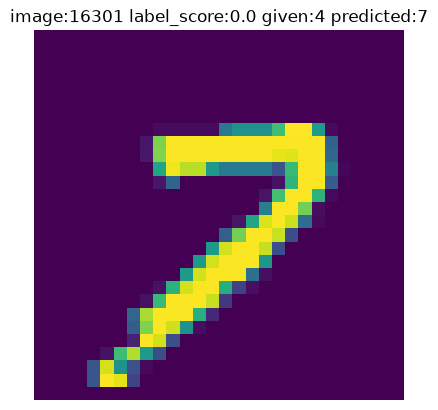

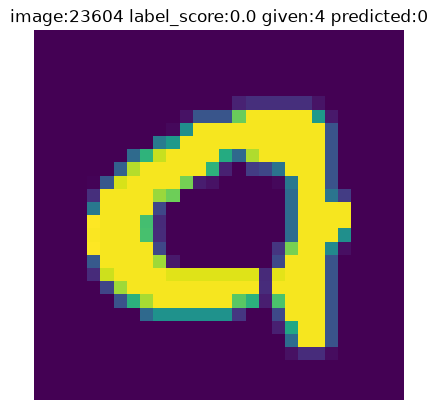

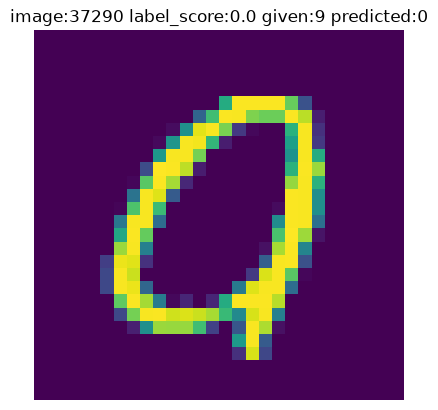

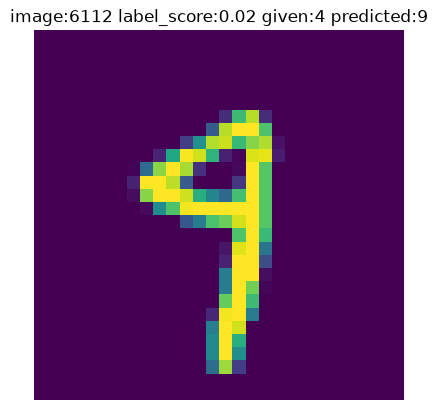

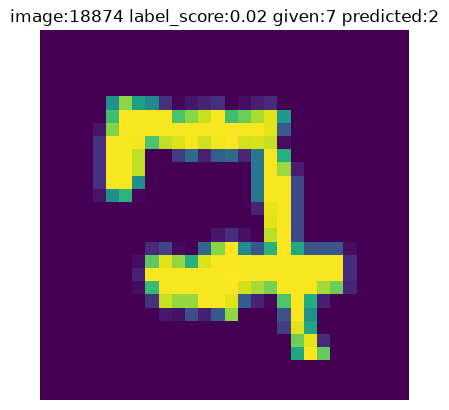

In [10]:
for r in df.head(5).itertuples():
    i = r[0]
    label_score = r[2]
    given = r[3]
    predicted = r[4]
    title = f'image:{i} label_score:{label_score} given:{given} predicted:{predicted}'
    print_image(title, i, X)

##### Handling problematic records

There are 2 approachs:
- simply remove problematic records from the dataset
- fix erroneous labels were possible. For example: image 16301 is annotated as 4, but the actual image is obviously 7.

In this dataset, only 35 label issues were found in 70,000 records (only 0.5%).
So I decided chose option 1.

Removing these records and retraining increase precision from 0.97 to 1.00.

In [11]:
# Identify the indices of the problematic records
issue_indices = find_label_issues(
    labels=y, 
    pred_probs=pred_probs, 
    return_indices_ranked_by="self_confidence"
)

print(f"Cleanlab flagged {len(issue_indices)} problematic records.")

# 3. Drop the bad records from your training arrays/DataFrame
# (Assuming X_train and y_train are NumPy arrays or Pandas objects)
X_clean = np.delete(X, issue_indices, axis=0)
y_clean = np.delete(y, issue_indices, axis=0)

# 4. Retrain your final model on the clean dataset
final_clf = RandomForestClassifier(random_state=42)
final_clf.fit(X_clean, y_clean)

Cleanlab flagged 43 problematic records.


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

##### examine results

When problematic records were removed, accuracy increased from 0.97 to 1.00.

In [12]:
pred=final_clf.predict(X_clean)
print ("Classification Report")
print(classification_report(y_clean, pred))
print ("Confusion Report")
cm_clean = confusion_matrix(y_clean, pred)
print(cm_clean)
accuracy = np.diag(cm_clean).sum() / cm_clean.sum() # accuracy is proportion of values on the diagonal
print(f'accuracy: {accuracy:.4f}')

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6916
           1       1.00      1.00      1.00      7880
           2       1.00      1.00      1.00      7019
           3       1.00      1.00      1.00      7115
           4       1.00      1.00      1.00      6819
           5       1.00      1.00      1.00      6286
           6       1.00      1.00      1.00      6913
           7       1.00      1.00      1.00      7282
           8       1.00      1.00      1.00      6765
           9       1.00      1.00      1.00      6962

    accuracy                           1.00     69957
   macro avg       1.00      1.00      1.00     69957
weighted avg       1.00      1.00      1.00     69957

Confusion Report
[[6916    0    0    0    0    0    0    0    0    0]
 [   0 7880    0    0    0    0    0    0    0    0]
 [   0    0 7019    0    0    0    0    0    0    0]
 [   0    0    0 7115    0    0    0    0  